# Jumbleberry Fields — strategy analytics

How good is *good* at Jumbleberry Fields, and what does perfect play look like?

This notebook establishes baselines for a ladder of strategies, from random clicking to provably perfect play, and compares them with real games. It covers:

1. **The game in numbers**: berry odds, boxes, prize thresholds, and how hard each box is.
2. **The perfect player**: an exact dynamic-programming solver (not an approximation).
3. **The strategy ladder**: random play, simple heuristics, human-style play, and optimal play, 200,000 simulated games each.
4. **Real games**: 21 logged human games, plus Claude Opus 5.5 playing games by its own judgement.
5. **Prizes**: which goal wins the most Moonberries over time.
5. **What perfect play does**: lessons a human can use, including a *par sheet* that gets within 2 points of perfect.
6. **AI models**: tabular Q-learning and a deep Q-network (DQN), benchmarked against the exact optimum.

Everything is computed from the code in this folder: `engine.py`, `solver.py`, `strategies.py`, `rl_*.py`. Re-run `baselines.py` to regenerate the cached simulations.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from engine import (BERRIES, CATEGORIES, CATEGORY_LABELS, VALUES, PROBS, SCORES, HANDS, KEEPS,
                    FIRST_ROLL, TRANSITION, SUBKEEPS, MAX_SCORE, N_HANDS, names_from_counts)
from solver import ExpectedScoreSolver, ThresholdSolver, score_distribution
from strategies import simulate, par_sheet, TUNED_PAR, _single_box_chase_tables
import baselines

pd.set_option('display.precision', 2)

# Chart style: validated reference palette, thin marks, hairline grid
C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100', magenta='#e87ba4',
         green='#008300', violet='#6250d6', red='#e34948')
INK, INK2, MUTED, GRID, AXIS, SURF = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
GRAY = '#b9b8b1'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'Helvetica', 'DejaVu Sans'],
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
    'axes.titlepad': 12, 'legend.frameon': False, 'figure.dpi': 110, 'lines.linewidth': 2})

def threshold_lines(ax, labels=True):
    # staggered so the two labels never collide
    for t, lab, h in ((121, '121 · 1 Moonberry', 0.97), (141, '141 · 2 Moonberries', 0.89)):
        ax.axvline(t, color=MUTED, lw=1, zorder=1)
        if labels:
            ax.text(t + 1.5, ax.get_ylim()[1] * h, lab, color=INK2, fontsize=8.5, va='top')

ev = ExpectedScoreSolver()
th = ThresholdSolver(ev)            # cached in models/threshold_solver.npz after the first run
sims = baselines.load_or_run()      # 200k games per strategy, cached in data/strategy_sims.npz
s_axis = np.arange(MAX_SCORE + 1)

## 1. The game in numbers

Each of the five jars is a 10-sided die: 3 Jumbleberry faces, 3 Sugarberry, 2 Pickleberry, 1 Moonberry and 1 Fly (a pest).
Each round you roll up to three times, locking any jars you like between rolls, then score the jars in one of nine boxes. Every box is used exactly once, and a box can take a 0. There is no bonus.

**Prizes** ([webkinzguide](https://webkinzguide.com/wiki/Jumbleberry_Fields)): **121+ earns a Moonberry, 141+ earns two.** 140 also gets the *Berry Farmer* badge. The maximum possible score is 237.

In [2]:
pd.DataFrame({'points': VALUES, 'faces of 10': (PROBS * 10).astype(int), 'chance per jar': PROBS},
             index=BERRIES).style.format({'chance per jar': '{:.0%}'})

,points,faces of 10,chance per jar
Jumbleberry,2,3,30%
Sugarberry,2,3,30%
Pickleberry,4,2,20%
Moonberry,7,1,10%
Fly,0,1,10%


**How hard is each box on its own?** If you spent a whole round (three rolls) chasing *only* one box, starting from scratch, the table below shows what you'd get on average and how often you'd qualify at all.
Basket of 5 is a long shot (about 1 in 9 even when chasing it), which turns out to matter for strategy.

In [3]:
E1, E2, K1c, K2c = _single_box_chase_tables()
def chase_qualify_prob(c):
    # best achievable P(box scores > 0) when chasing only box c for one round
    e = (SCORES[:, c] > 0).astype(float)
    for _ in range(2):
        e = (TRANSITION @ e)[SUBKEEPS].max(1)
    return FIRST_ROLL @ e
pd.DataFrame({
    'max points': SCORES.max(0),
    'avg points when chased': E1 @ FIRST_ROLL,
    'P(qualify) when chased': [chase_qualify_prob(c) if c >= 4 and c != 8 else np.nan for c in range(9)],
}, index=CATEGORY_LABELS).style.format({'avg points when chased': '{:.1f}', 'P(qualify) when chased': '{:.1%}'}, na_rep='—')

,max points,avg points when chased,P(qualify) when chased
Jumbleberry,10,6.6,—
Sugarberry,10,6.6,—
Pickleberry,20,9.8,—
Moonberry,35,9.5,—
Basket of 3,35,13.8,93.2%
Basket of 4,35,7.3,60.0%
Basket of 5,35,2.0,18.6%
Mixed Basket,22,9.4,51.7%
Free Roll,35,19.4,—


## 2. The perfect player: solving the game exactly

The game is small enough to **solve exactly**, so no neural network is needed to find the best strategy.

Because there's no bonus, the only thing about your scorecard that affects your future is **which boxes are still open**: 2⁹ = 512 possibilities. Jar order doesn't matter, so there are only **126 distinct hands** and **252 possible locks**. Working backwards from the last round (dynamic programming) gives the exact value of every position and the best move in it. It takes a fraction of a second.

A second solver maximises **the chance of reaching a target score** (121 or 141) instead of the average. That needs the points still required as part of the state. It takes about a minute and covers every target from 1 to 237 at once.

In [4]:
p_opt = score_distribution(ev.cat, ev.keep1, ev.keep2)      # exact final-score distribution
mean_opt = (p_opt * s_axis).sum()
sd_opt = np.sqrt((p_opt * s_axis**2).sum() - mean_opt**2)
pd.DataFrame({
    'value': [f'{mean_opt:.2f}', f'{sd_opt:.1f}', f'{p_opt[121:].sum():.1%}', f'{p_opt[141:].sum():.1%}',
              f'{th.prob(121):.1%}', f'{th.prob(141):.1%}', f'{ev.solve_seconds:.2f} s'],
}, index=['Optimal average score', 'Standard deviation', 'P(121+) playing for best average',
          'P(141+) playing for best average', 'P(121+) best possible (playing for 121)',
          'P(141+) best possible (playing for 141)', 'Solve time (average solver)'])

,value
Optimal average score,121.80
Standard deviation,13.8
P(121+) playing for best average,54.0%
P(141+) playing for best average,8.5%
P(121+) best possible (playing for 121),57.9%
P(141+) best possible (playing for 141),11.0%
Solve time (average solver),0.05 s


**This is the key fact for prize hunters.** The 1-Moonberry line (121) sits right on top of the perfect player's average (121.8). Even flawless play earns that prize only about **55–58%** of the time, and two Moonberries only **8.5–11%** of the time. When players say the top prize is hard to get, the math agrees: perfect play misses it about 9 games in 10.

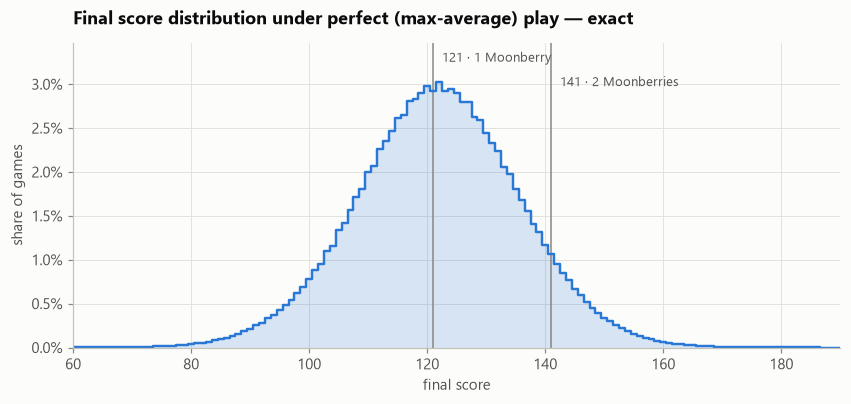

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(s_axis, p_opt, step='mid', color=C['blue'], alpha=0.18, lw=0)
ax.step(s_axis, p_opt, where='mid', color=C['blue'], lw=1.6)
ax.set_xlim(60, 190); ax.set_ylim(0, p_opt.max() * 1.15)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
threshold_lines(ax)
ax.set_title('Final score distribution under perfect (max-average) play — exact')
ax.set_xlabel('final score'); ax.set_ylabel('share of games')
plt.show()

## 3. The strategy ladder

Every strategy below played the same 200,000 simulated games. The **pts lost/game** column grades decisions rather than luck: at every decision it measures how many expected points the move gave away compared with the perfect move. 0 means perfect play.

| Strategy | What it does |
|---|---|
| Random | locks a random set of jars, scores in a random open box (the original random simulation) |
| Random locks, best box | random locks, then the open box worth the most points (the original "semi-random" simulation) |
| One roll, best box | never re-rolls |
| Keep most common, best box | the classic Yahtzee instinct: lock the biggest matching group |
| High-roller | chase baskets, Mixed Baskets and Moonberries, use Jumbleberry/Sugarberry as throw-aways |
| Best single round | perfect tactics for *this round's* points, no thought for future rounds |
| Target box + par sheet | human-style: pick one box to chase each roll, and score by "points minus par" (section 5) |
| Optimal (max average) | the exact solver |
| Optimal for ≥121 / ≥141 | the exact solver, maximising the chance of each prize |

In [6]:
human = json.load(open('game_results.json'))
human_keys = ['Jumbleberry', 'Sugarberry', 'Pickleberry', 'Moonberry', 'Basket of 3',
              'Basket of 4', 'Basket of 5', 'Mixed Basket', 'Free Roll']
human_boxes = np.array([[int(g[k]) for k in human_keys] for g in human])
human_total = human_boxes.sum(1)

claude_games = [json.loads(l) for l in open('data/agent_games.jsonl')] if os.path.exists('data/agent_games.jsonl') else []
CLAUDE = 'claude-opus-5.5'   # games played by Claude Opus 5.5 through agent_play.py
claude_games = [g for g in claude_games if g['player'] == CLAUDE]
claude_total = np.array([g['score'] for g in claude_games])

rows = [r.summary() for r in sims.values()]
def real_row(name, t, lost=np.nan):
    return {'strategy': name, 'games': len(t), 'mean': t.mean(), 'sd': t.std(), 'p10': np.percentile(t, 10),
            'median': np.median(t), 'p90': np.percentile(t, 90), 'max': t.max(),
            'P(>=121)': (t >= 121).mean(), 'P(>=141)': (t >= 141).mean(), 'pts lost/game': lost}
rows.append(real_row('Human: 21 logged games', human_total))
if len(claude_total):
    from review import grade_game
    lost = np.mean([sum(d['regret'] for d in grade_game(g, ev)) for g in claude_games])
    rows.append(real_row(f'Claude Opus 5.5: {len(claude_total)} games', claude_total, lost))
ladder = pd.DataFrame(rows).set_index('strategy').sort_values('mean')
# Skill estimate from decisions alone (removes dice luck): perfect average minus points given away
ladder['decision-quality avg'] = mean_opt - ladder['pts lost/game']
ladder.style.format({'mean': '{:.1f}', 'sd': '{:.1f}', 'p10': '{:.0f}', 'median': '{:.0f}', 'p90': '{:.0f}',
                     'P(>=121)': '{:.1%}', 'P(>=141)': '{:.1%}', 'pts lost/game': '{:.1f}', 'games': '{:,}', 'decision-quality avg': '{:.1f}'}, na_rep='—')

,games,mean,sd,p10,median,p90,max,P(>=121),P(>=141),pts lost/game,decision-quality avg
strategy,,,,,,,,,,,
Random,"200,000",35.0,12.1,20,34,51,100,0.0%,0.0%,86.8,35.0
"Random locks, best box","200,000",63.4,13.2,46,64,80,124,0.0%,0.0%,58.4,63.4
"One roll, best box","200,000",63.4,13.3,46,64,80,137,0.0%,0.0%,58.4,63.4
"Keep most common, best box","200,000",79.0,15.7,60,78,100,163,1.0%,0.0%,42.8,79.0
High-roller (J/S as throw-aways),"200,000",105.7,15.9,86,106,126,183,17.2%,1.4%,16.1,105.7
Best single round (no planning),"200,000",109.4,13.6,92,109,127,176,20.1%,1.4%,12.4,109.4
Human: 21 logged games,21,114.9,14.6,93,117,127,144,28.6%,4.8%,—,—
Optimal for >= 141 (2 Moonberries),"200,000",116.2,16.7,95,114,141,187,35.4%,10.9%,5.6,116.2
Optimal for >= 121 (1 Moonberry),"200,000",119.3,15.2,97,122,137,182,57.9%,5.9%,2.5,119.3


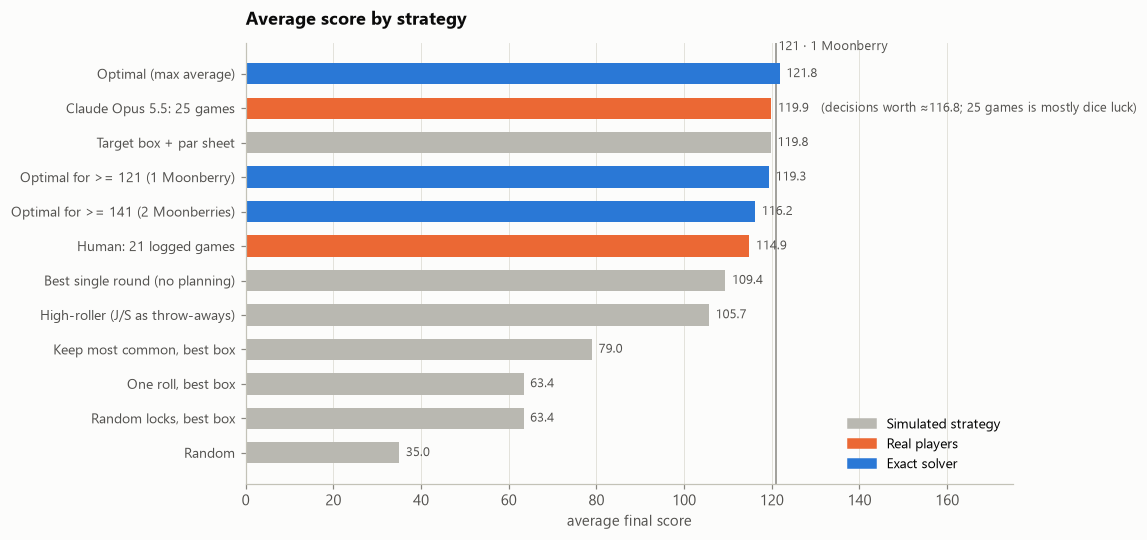

In [7]:
def group(name):
    if name.startswith(('Human', 'Claude')): return 'Real players'
    if name.startswith('Optimal'): return 'Exact solver'
    return 'Simulated strategy'
gcol = {'Simulated strategy': GRAY, 'Real players': C['orange'], 'Exact solver': C['blue']}
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(ladder))
for i, (name, r) in enumerate(ladder.iterrows()):
    ax.barh(i, r['mean'], height=0.62, color=gcol[group(name)], zorder=2)
    note = (f"   (decisions worth ≈{r['decision-quality avg']:.1f}; {int(r['games'])} games is mostly dice luck)"
            if name.startswith('Claude') else '')
    ax.text(r['mean'] + 1.5, i, f"{r['mean']:.1f}{note}", va='center', fontsize=8.5, color=INK2)
ax.set_yticks(y, ladder.index, fontsize=9)
ax.axvline(121, color=MUTED, lw=1, zorder=1)
ax.text(121.5, len(ladder) - 0.4, '121 · 1 Moonberry', fontsize=8.5, color=INK2, va='bottom')
ax.set_xlim(0, 175); ax.grid(axis='y', visible=False)
ax.set_xlabel('average final score')
ax.set_title('Average score by strategy')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=g) for g, col in gcol.items()], loc='lower right', fontsize=9)
plt.show()

Reading the ladder:

* **Random clicking scores about 35.** Locking random jars is no better than never re-rolling (both about 63). The gains come from *what* you lock and *which box* you score.
* **The par sheet is worth more than any locking rule.** "Best single round" has perfect within-round tactics but greedily takes the biggest box every time, and stalls at 109. Choosing boxes with a par sheet instead jumps to about 120.
* **Playing for a prize trades average points for prize odds.** The ≥141 player gives up 5.6 average points to raise P(141+) from 8.4% to 10.9%.

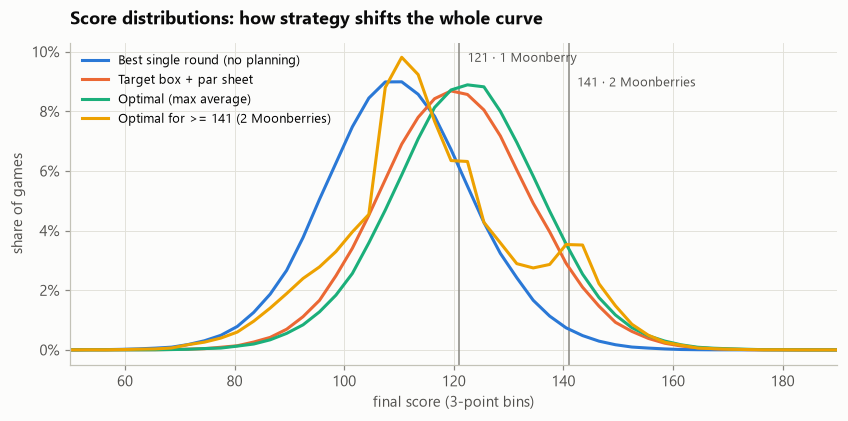

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
show = [('Best single round (no planning)', C['blue']), ('Target box + par sheet', C['orange']),
        ('Optimal (max average)', C['aqua']), ('Optimal for >= 141 (2 Moonberries)', C['yellow'])]
bins = np.arange(40, 200, 3)
for name, col in show:
    h, _ = np.histogram(sims[name].total, bins=bins)
    ax.plot(bins[:-1] + 1.5, h / h.sum(), color=col, lw=2, label=name)
ax.set_xlim(50, 190); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
threshold_lines(ax)
ax.set_xlabel('final score (3-point bins)'); ax.set_ylabel('share of games')
ax.set_title('Score distributions: how strategy shifts the whole curve')
ax.legend(fontsize=8.5, loc='upper left')
plt.show()

### Chasing a prize: the best possible odds for every target

The **blue line** is the best achievable P(final score ≥ target) for each target, with the solver re-optimised for every target. No strategy can be above it at any point. The other lines show how close each player type gets.

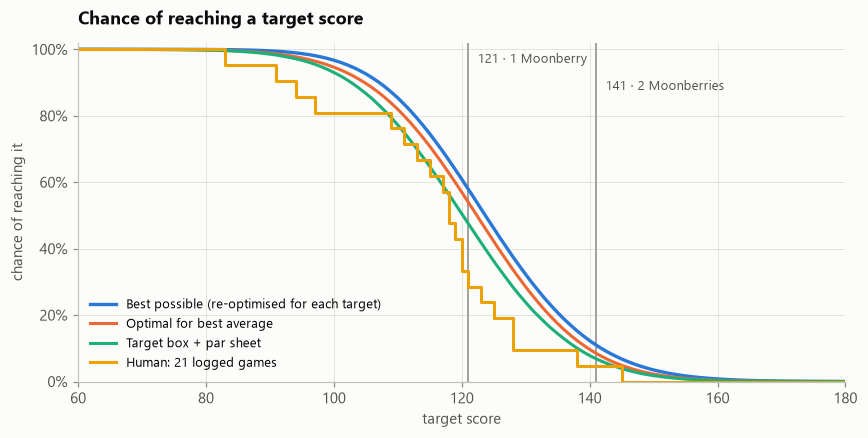

,best possible,optimal-average play
target,,
100,96.7%,94.6%
110,85.4%,81.9%
121,57.9%,54.0%
130,32.2%,28.5%
141,11.0%,8.5%
150,3.5%,2.2%
160,0.8%,0.4%


In [9]:
targets = np.arange(60, 181)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(targets, [th.prob(t) for t in targets], color=C['blue'], lw=2.2, label='Best possible (re-optimised for each target)')
ax.plot(targets, [p_opt[t:].sum() for t in targets], color=C['orange'], lw=2, label='Optimal for best average')
par_t = sims['Target box + par sheet'].total
ax.plot(targets, [(par_t >= t).mean() for t in targets], color=C['aqua'], lw=2, label='Target box + par sheet')
ax.plot(targets, [(human_total >= t).mean() for t in targets], color=C['yellow'], lw=2, drawstyle='steps-post',
        label='Human: 21 logged games')
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_xlim(60, 180)
threshold_lines(ax)
ax.set_xlabel('target score'); ax.set_ylabel('chance of reaching it')
ax.set_title('Chance of reaching a target score')
ax.legend(fontsize=8.5, loc='lower left')
plt.show()
pd.DataFrame({'best possible': [th.prob(t) for t in (100, 110, 121, 130, 141, 150, 160)],
              'optimal-average play': [p_opt[t:].sum() for t in (100, 110, 121, 130, 141, 150, 160)]},
             index=pd.Index([100, 110, 121, 130, 141, 150, 160], name='target')).style.format('{:.1%}')

### Which goal wins the most Moonberries over time?

The real game pays **1 Moonberry for 121–140 and 2 for 141+**. Over many days, what matters is Moonberries per game: P(121+) + P(141+).
`PrizeSolver({121: 1, 141: 1})` maximises exactly that. The state is the open boxes plus the points banked so far, capped at 141.

In [10]:
from solver import PrizeSolver
ps = PrizeSolver({121: 1, 141: 1}, ev)
moon = simulate(ps.policy(), 200_000, seed=7).total
def moon_row(t, exact=None):
    return {'Moonberries per 100 games': 100 * (exact if exact is not None else (t >= 121).mean() + (t >= 141).mean()),
            'P(121+)': (t >= 121).mean(), 'P(141+)': (t >= 141).mean(), 'average score': t.mean()}
pd.DataFrame({
    'Most Moonberries (PrizeSolver)': moon_row(moon, ps.expected_prize),
    'Play for 1 Moonberry (121+)': moon_row(sims['Optimal for >= 121 (1 Moonberry)'].total),
    'Highest average score': moon_row(sims['Optimal (max average)'].total),
    'Play for 2 Moonberries (141+)': moon_row(sims['Optimal for >= 141 (2 Moonberries)'].total),
    'Par sheet': moon_row(sims['Target box + par sheet'].total),
}).T.style.format({'Moonberries per 100 games': '{:.1f}', 'P(121+)': '{:.1%}', 'P(141+)': '{:.1%}', 'average score': '{:.1f}'})

,Moonberries per 100 games,P(121+),P(141+),average score
Most Moonberries (PrizeSolver),66.8,57.4%,9.3%,119.5
Play for 1 Moonberry (121+),63.8,57.9%,5.9%,119.3
Highest average score,62.5,54.1%,8.4%,121.8
Play for 2 Moonberries (141+),46.3,35.4%,10.9%,116.2
Par sheet,54.5,47.6%,6.9%,119.8


* **Most Moonberries wins: 66.8 per 100 games.** It plays for 121 first. Once 121 looks likely with rounds to spare, it takes risks for 141. It gives up half a point of the first Moonberry's odds (57.4% vs 57.9%) to lift the second from 5.9% to 9.3%.
* **Between the two fixed goals, play for 1 Moonberry.** It wins 63.8 per 100 games against 46.3 for always chasing 141, which is 38% more over time. Chasing 141 throws away too many 121-ish games.
* **Playing for the highest average (62.5) is close behind the 121 goal.** The prize lines sit so near the perfect average that the two goals agree most of the time.

`site/helper.html` uses the Most Moonberries goal by default.

## 4. Real games

### 21 logged human games

These were played on the command-line version of the game. Note that it had a bug at the time: locking one berry locked *every* jar of that type. Re-solving the game under that rule shows the bug costs even a perfect player only about 0.6 points (121.2 vs 121.8), so the comparison below is still fair.

In [11]:
print(f'Human average {human_total.mean():.1f} (sd {human_total.std():.1f}, best {human_total.max()}) '
      f'= {human_total.mean() / mean_opt:.1%} of perfect play')
print(f'Human P(121+) = {(human_total >= 121).mean():.0%} ({(human_total >= 121).sum()}/21), '
      f'P(141+) = {(human_total >= 141).mean():.0%} ({(human_total >= 141).sum()}/21)')
opt_boxes = sims['Optimal (max average)'].cat_scores
box = pd.DataFrame({'human avg': human_boxes.mean(0), 'optimal avg': opt_boxes.mean(0),
                    'human zero rate': (human_boxes == 0).mean(0), 'optimal zero rate': (opt_boxes == 0).mean(0)},
                   index=CATEGORY_LABELS)
box['gap'] = box['human avg'] - box['optimal avg']
box.style.format({'human avg': '{:.1f}', 'optimal avg': '{:.1f}', 'gap': '{:+.1f}',
                  'human zero rate': '{:.0%}', 'optimal zero rate': '{:.0%}'})

Human average 114.9 (sd 14.6, best 144) = 94.3% of perfect play
Human P(121+) = 29% (6/21), P(141+) = 5% (1/21)


,human avg,optimal avg,human zero rate,optimal zero rate,gap
Jumbleberry,5.5,6.7,0%,0%,-1.2
Sugarberry,5.0,6.7,0%,0%,-1.7
Pickleberry,12.0,11.5,0%,0%,+0.5
Moonberry,15.3,14.8,10%,4%,+0.5
Basket of 3,21.5,20.9,0%,1%,+0.6
Basket of 4,11.9,15.8,19%,6%,-3.9
Basket of 5,7.1,6.4,52%,45%,+0.7
Mixed Basket,16.6,18.2,10%,3%,-1.6
Free Roll,19.9,20.9,0%,0%,-1.0


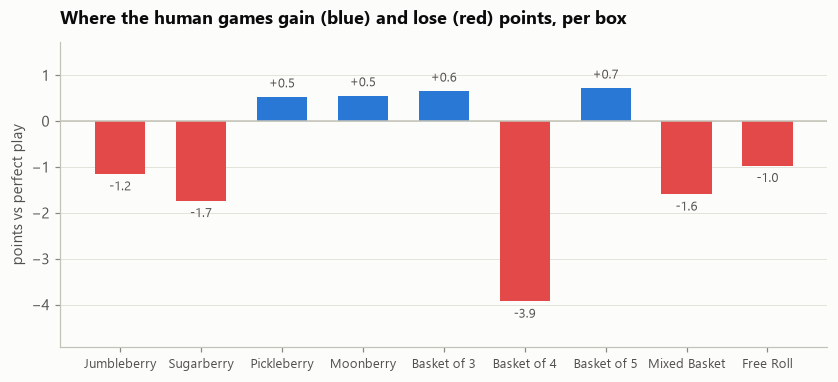

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
gap = box['gap'].values
cols = [C['blue'] if g >= 0 else C['red'] for g in gap]
ax.bar(np.arange(9), gap, color=cols, width=0.62, zorder=2)
ax.axhline(0, color=AXIS, lw=1)
for i, g in enumerate(gap):
    ax.text(i, g + (0.15 if g >= 0 else -0.15), f'{g:+.1f}', ha='center', va='bottom' if g >= 0 else 'top',
            fontsize=8.5, color=INK2)
ax.set_xticks(np.arange(9), CATEGORY_LABELS, fontsize=8.5)
ax.grid(axis='x', visible=False); ax.set_ylim(gap.min() - 1, gap.max() + 1)
ax.set_ylabel('points vs perfect play')
ax.set_title('Where the human games gain (blue) and lose (red) points, per box')
plt.show()

The human games are strong: about 94% of perfect. The leaks are specific:

* **Basket of 4 is the biggest leak** (about −4 points). It was zeroed in 19% of games vs 6% for perfect play.
* **Jumbleberry and Sugarberry lose about 3 points combined.** Using them as throw-aways is costly. The perfect player almost never zeroes them (0.5%) and averages 6.7 in each, which is three or more berries.
* **Mixed Basket** was zeroed twice as often as optimal (10% vs 3.5%).
* **The real throw-away box is Basket of 5.** The perfect player zeroes it 45% of the time and plans for that.

Small sample caveat: with 21 games, each per-box average has an uncertainty of about ±1–2 points.

### The original simulations (with the keep bug) vs corrected

In [13]:
old = {f: np.array([int(g['Score']) for g in json.load(open(f))]) for f in ['random_game_results.json', 'semi_random_game_results.json']}
pd.DataFrame({
    'original sim (1,000 games, keep bug)': [old['random_game_results.json'].mean(), old['semi_random_game_results.json'].mean()],
    'corrected (200,000 games)': [sims['Random'].total.mean(), sims['Random locks, best box'].total.mean()]},
    index=['Random', 'Random locks, best box']).style.format('{:.1f}')

,"original sim (1,000 games, keep bug)","corrected (200,000 games)"
Random,37.7,35.0
"Random locks, best box",67.1,63.4


### Claude Opus 5.5 playing by its own judgement

Five separate Claude Opus 5.5 instances played games in parallel through `agent_play.py` (one save slot each). They were given the rules and berry odds only: no solver, no code, no data, and an instruction to reason through each move. Every decision was logged and graded against the perfect move.

An earlier 5-game pilot, logged as player `claude`, is excluded here. One game includes an input slip: the player sent two lock commands at once and re-rolled a Moonberry it meant to keep. That cost about 7 points, roughly 0.3 points on the per-game average.

In [14]:
if claude_games:
    from review import grade_game, best_move_text
    rows, worst = [], []
    for i, g in enumerate(claude_games):
        gr = grade_game(g, ev)
        lost = sum(d['regret'] for d in gr)
        bad = [d for d in gr if d['regret'] > 0.05]
        rows.append({'game': i + 1, 'score': g['score'], 'decisions': len(gr), 'sub-optimal': len(bad),
                     'expected pts given away': lost})
        worst += [{'game': i + 1, 'round': d['round'], 'roll': d['roll'], 'jars': ' '.join(d['jars']),
                   'Claude did': d['move'], 'best move': best_move_text(d), 'cost (pts)': d['regret']} for d in bad]
    display(pd.DataFrame(rows).set_index('game').style.format({'expected pts given away': '{:.1f}'}))
    se = claude_total.std(ddof=1) / np.sqrt(len(claude_total))
    all_d = [d for g in claude_games for d in grade_game(g, ev)]
    lost_keep = sum(d['regret'] for d in all_d if d['action'] == 'keep') / len(claude_games)
    lost_box = sum(d['regret'] for d in all_d if d['action'] == 'score') / len(claude_games)
    print(f"{len(claude_total)} games: average score {claude_total.mean():.1f} (95% CI {claude_total.mean() - 1.96 * se:.1f} to "
          f"{claude_total.mean() + 1.96 * se:.1f}); P(121+) {np.mean(claude_total >= 121):.0%}, P(141+) {np.mean(claude_total >= 141):.0%}")
    print(f"Expected points given away per game: {np.mean([r['expected pts given away'] for r in rows]):.2f} "
          f"(locking {lost_keep:.2f}, choosing boxes {lost_box:.2f}); perfect moves {np.mean([d['regret'] <= 0.05 for d in all_d]):.1%} "
          f"of {len(all_d)} decisions; skill estimate {mean_opt - np.mean([r['expected pts given away'] for r in rows]):.1f}")
    display(pd.DataFrame(worst).sort_values('cost (pts)', ascending=False).head(10).set_index('game')
            .style.format({'cost (pts)': '{:.2f}'}))
else:
    print('No Claude games logged yet (data/agent_games.jsonl).')

,score,decisions,sub-optimal,expected pts given away
game,,,,
1,135,22,3,4.3
2,115,24,4,8.2
3,124,25,4,4.3
4,128,27,3,1.2
5,79,27,11,9.9
6,130,25,3,1.6
7,118,25,6,7.4
8,106,25,12,12.3
9,121,27,6,5.0


25 games: average score 119.9 (95% CI 113.3 to 126.5); P(121+) 60%, P(141+) 4%
Expected points given away per game: 4.96 (locking 2.76, choosing boxes 2.20); perfect moves 78.7% of 638 decisions; skill estimate 116.8


,round,roll,jars,Claude did,best move,cost (pts)
game,,,,,,
17,9,2,Fly Moonberry Sugarberry Moonberry Fly,lock Moonberry,"Lock Moonberry, Moonberry and re-roll 3",6.30
2,5,3,Jumbleberry Jumbleberry Jumbleberry Jumbleberry Pickleberry,score 12 in Basket of 3,Score 8 in Jumbleberry,6.10
15,3,1,Moonberry Sugarberry Sugarberry Moonberry Sugarberry,score 20 in Basket of 3,"Lock Moonberry, Moonberry and re-roll 3",4.77
8,1,1,Pickleberry Sugarberry Sugarberry Moonberry Sugarberry,score 17 in Basket of 3,"Lock Pickleberry, Moonberry and re-roll 3",4.12
10,2,3,Pickleberry Pickleberry Sugarberry Sugarberry Sugarberry,score 14 in Basket of 3,Score 6 in Sugarberry,3.21
11,7,3,Sugarberry Sugarberry Sugarberry Pickleberry Jumbleberry,score 12 in Basket of 3,Score 6 in Sugarberry,2.83
7,3,2,Sugarberry Sugarberry Moonberry Moonberry Sugarberry,score 20 in Basket of 3,"Lock Moonberry, Moonberry and re-roll 3",2.76
1,3,1,Pickleberry Jumbleberry Jumbleberry Moonberry Jumbleberry,score 17 in Basket of 3,"Lock Pickleberry, Moonberry and re-roll 3",2.58
17,5,3,Moonberry Sugarberry Sugarberry Sugarberry Fly,score 13 in Basket of 3,Score 6 in Sugarberry,2.44


**Claude Opus 5.5 averaged 119.9 over 25 games**, but the grading says its decisions are worth about **116.8**. It gave away about 5 expected points a game and made the perfect move 79% of the time, so it ran slightly lucky. That is still a strong unaided player: about 2 points above the human games' 114.9, though those weren't graded move by move, and 3 points below the par sheet. Locking mistakes cost about 2.8 points a game and box choices about 2.2.

Its costliest habits:

* **Spending Basket of 3 on modest hands.** This was the biggest leak by far. Examples: 17 points from `P J J M J` on a first roll instead of locking `P M`, or 12 points from `J J J J P` instead of 8 in Jumbleberry. Perfect play saves Basket of 3 for big totals (it averages about 21 there) and often puts three or four Jumbleberries or Sugarberries in their own box.
* **Four of a kind of Jumble/Sugar in Basket of 4** (10 points) instead of their own box (8). It also stopped rolling on four of a kind instead of trying for five.
* **Locking a big group of cheap berries over Moonberries**, for example keeping `S S S` from `S M M S S`.
* The single largest cost (6.3) is the input slip described above.

## 5. What perfect play actually does

### Box by box

In [15]:
opt = sims['Optimal (max average)']
pd.DataFrame({'avg points': opt.cat_scores.mean(0), 'zeroed': (opt.cat_scores == 0).mean(0),
              'avg round filled': opt.fill_round.mean(0)}, index=CATEGORY_LABELS
             ).sort_values('avg round filled').style.format({'avg points': '{:.1f}', 'zeroed': '{:.1%}', 'avg round filled': '{:.1f}'})

,avg points,zeroed,avg round filled
Mixed Basket,18.2,3.5%,4.0
Basket of 3,20.9,0.9%,4.3
Basket of 4,15.8,5.5%,4.7
Sugarberry,6.7,0.4%,5.2
Jumbleberry,6.7,0.4%,5.2
Free Roll,20.9,0.0%,5.2
Pickleberry,11.5,0.5%,5.4
Moonberry,14.8,3.6%,5.4
Basket of 5,6.4,44.9%,5.5


In [16]:
ru = opt.rolls_used.ravel()
print('Rolls used per round (perfect play): ' + ', '.join(f'{k} roll{"s" if k > 1 else ""} {np.mean(ru == k):.1%}' for k in (1, 2, 3)))

Rolls used per round (perfect play): 1 roll 1.5%, 2 rolls 9.3%, 3 rolls 89.3%


* **Mixed Basket and Basket of 3 get filled earliest.** Take them when they come.
* **Basket of 5 and Moonberry get filled last.** They're the late-game gambles, and Basket of 5 is the dump box.
* **Perfect play almost always uses all three rolls** (89% of rounds).

### Locking habits of the perfect player

How often perfect play locks berries it is holding, measured over every re-roll decision in 100,000 games:

In [17]:
from engine import roll, EMPTY_KEEP, HAND_TO_KEEP, OPEN
rng = np.random.default_rng(0); n = 100_000; mask = np.zeros(n, int); H, K, Mk = [], [], []
for rnd in range(9):
    hand = roll(np.full(n, EMPTY_KEEP), rng)
    for rl in (2, 1):
        k = (ev.keep1 if rl == 2 else ev.keep2)[mask, hand]
        H.append(hand.copy()); K.append(k.copy()); Mk.append(mask.copy())
        hand = np.where(k == HAND_TO_KEEP[hand], hand, roll(k, rng))
    mask |= 1 << ev.cat[mask, hand]
H, K, Mk = map(np.concatenate, (H, K, Mk)); hc, kc = HANDS[H], KEEPS[K]
reroll = K != HAND_TO_KEEP[H]
def lock_rate(sel, t): return np.mean(kc[sel, t] == hc[sel, t])
rows = []
for t, nm in [(3, 'Moonberries'), (2, 'Pickleberries'), (4, 'Flies')]:
    sel = (hc[:, t] >= 1) & reroll
    row = {'holding': f'any {nm}', 'locks all of them': lock_rate(sel, t)}
    if t < 4:
        row['…while its own box is open'] = lock_rate(sel & OPEN[Mk, t], t)
    rows.append(row)
for c in (2, 3, 4):
    sel = ((hc[:, 0] == c) | (hc[:, 1] == c)) & reroll
    t = np.where(hc[sel, 0] == c, 0, 1)
    rows.append({'holding': f'exactly {c} Jumbleberries or Sugarberries',
                 'locks all of them': np.mean(kc[sel, t] == c)})
pd.DataFrame(rows).set_index('holding').style.format('{:.0%}', na_rep='—')

,locks all of them,…while its own box is open
holding,,
any Moonberries,84%,96%
any Pickleberries,66%,77%
any Flies,0%,—
exactly 2 Jumbleberries or Sugarberries,13%,—
exactly 3 Jumbleberries or Sugarberries,62%,—
exactly 4 Jumbleberries or Sugarberries,91%,—


### Opening moves (round 1, first roll)

In [18]:
order = np.argsort(-FIRST_ROLL)[:16]
pd.DataFrame([{'first roll': ' '.join(names_from_counts(HANDS[h], short=True)), 'chance': FIRST_ROLL[h],
               'perfect play locks': ' '.join(names_from_counts(KEEPS[ev.keep1[0, h]], short=True)) or '(re-roll all)'}
              for h in order]).style.format({'chance': '{:.1%}'}).hide(axis='index')

first roll,chance,perfect play locks
J J S S P,4.9%,P
J S S P P,3.2%,P P
J J S P P,3.2%,P P
J S S P F,3.2%,P
J J S P F,3.2%,P
J S S P M,3.2%,P M
J J S P M,3.2%,P M
J S S S P,3.2%,S S S
J J J S P,3.2%,J J J
J J S S M,2.4%,M


Some opening moves are surprising. With `J S S S M`, keep the single **Moonberry** and re-roll the three Sugarberries. With `J S P M F`, lock just `P M` rather than chasing the Mixed Basket in round 1.

### A par sheet a human can use

"Best single round" plays perfect tactics within a round but always grabs the biggest box. It scores 109. The difference between that and perfect play is mostly **which box you score**.

A **par** is what an open box is "worth" to you. Score each hand in the box where **points minus par** is highest, and each roll chase the one box you're most likely to beat par in. A coordinate search over whole-number pars found this sheet:

In [19]:
pd.DataFrame([TUNED_PAR.astype(int)], columns=CATEGORY_LABELS, index=['par'])

,Jumbleberry,Sugarberry,Pickleberry,Moonberry,Basket of 3,Basket of 4,Basket of 5,Mixed Basket,Free Roll
par,10,10,13,13,18,14,6,14,21


In [20]:
r = sims['Target box + par sheet']
print(f'Target box + par sheet: average {r.total.mean():.1f} ({r.total.mean() / mean_opt:.1%} of perfect), '
      f'P(121+) {np.mean(r.total >= 121):.1%}, P(141+) {np.mean(r.total >= 141):.1%}')

Target box + par sheet: average 119.8 (98.3% of perfect), P(121+) 47.6%, P(141+) 6.9%


Reading the sheet:

* **Jumbleberry and Sugarberry have par 10, their maximum.** Scoring three Jumbleberries (6 points) there "costs" 4 against par. They're not throw-aways.
* **Basket of 5 has par 6.** It's the throw-away. Dump a bad round there.
* **Free Roll has par 21**, the highest. Keep it open as a safety net for late rounds.
* **Mixed Basket has par 14**, below its average of about 18. A completed Mixed Basket is usually worth taking. The exception is early in the game: with two Pickleberries or Moonberries, re-rolling the cheap berries can be better.

The pars are tuned for this exact strategy. They are a decision tool, not a prediction of what you'll score in each box.

#### Four worked examples

Every example matches the exact solver's move in that spot. Only the first is an obvious call.

**1. A clear call.** Round 4, last roll, `P P P P M`; Jumbleberry, Sugarberry and Basket of 5 are used. **Basket of 4: 23 − 14 = +9**, Basket of 3 +5, Pickleberry +3, Free Roll +2, Moonberry −6. Score it in Basket of 4.

**2. Fewer points wins.** Round 5, last roll, `M M M J J`; Jumbleberry, Sugarberry, Pickleberry and Basket of 4 are used. **Moonberry: 21 − 13 = +8** beats Basket of 3 (25 − 18 = +7) and Free Roll (25 − 21 = +4). Take 21, not 25.

**3. Throw back three of a kind.** Round 2, first roll, `J J J S M`; only Free Roll is used. No box beats par from here. Chasing **Moonberry** (expect 12.3 vs par 13, −0.7) falls short by least: Basket of 3 is −1.6 and Jumbleberry −2.0. So **lock just the Moonberry** and re-roll the three Jumbleberries.

**4. When the round goes badly.** Round 6, last roll, `S J F J P` with Pickleberry, Moonberry, Basket of 4 and Basket of 5 open. **Basket of 5: 0 − 6 = −6** is the smallest loss; Pickleberry is 4 − 13 = −9. Take the zero in Basket of 5.

(Numbers from `TUNED_PAR` and `strategies._single_box_chase_tables()`; the same examples are drawn as charts in `site/dist/index.html`.)

## 6. AI models: can a learning agent find perfect play?

The exact solver is *planning*: it knows the berry probabilities and computes the answer. Reinforcement learning has to discover a strategy from experience alone, by playing millions of games and learning which moves led to points. Because the true optimum is known exactly, every agent's gap to perfect play can be measured.

| Model | How it learns | File |
|---|---|---|
| Tabular Q-learning | a table of values for all 193,536 states × 41 actions, updated after every move | `rl_qlearning.py` |
| Deep Q-network (DQN) | a small neural network (3 × 128 units) estimates move values from a 28-number board description; Double-DQN with action masking | `rl_dqn.py` |
| Exact DP solver | knows the probabilities and solves the game backwards | `solver.py` |

The environment (`rl_env.py`) models the full game: 41 actions are 31 jar-lock patterns plus 9 boxes, illegal moves are masked out, and thousands of games run in parallel. A standard `gymnasium` wrapper (`JumbleberryEnv`) is included for libraries such as Stable-Baselines3.

findfont: Font family ['STIXSizeThreeSym'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXSizeFourSym'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXSizeFiveSym'] not found. Falling back to DejaVu Sans.


findfont: Font family ['DejaVu Sans Display'] not found. Falling back to DejaVu Sans.


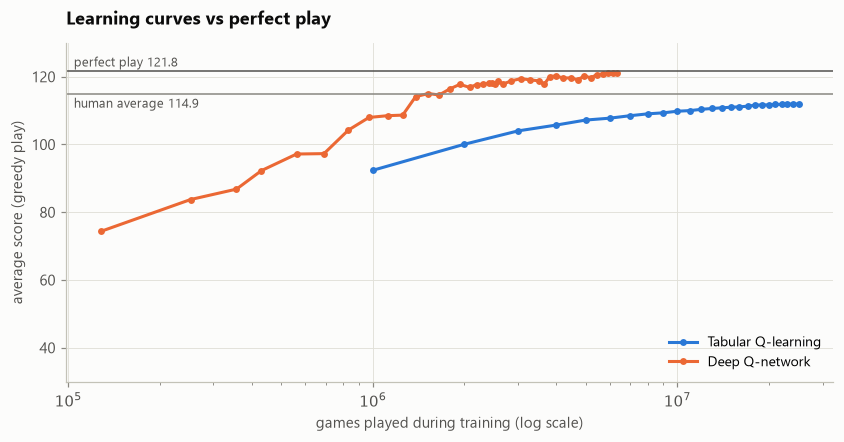

In [21]:
curves = {}
for name, f in [('Tabular Q-learning', 'models/q_learning_curve.json'), ('Deep Q-network', 'models/dqn_curve.json')]:
    if os.path.exists(f):
        curves[name] = json.load(open(f))
if curves:
    fig, ax = plt.subplots(figsize=(9, 4))
    for (name, d), col in zip(curves.items(), [C['blue'], C['orange']]):
        cv = [c for c in d['curve'] if c['games_trained'] > 0]
        ax.plot([c['games_trained'] for c in cv], [c['mean'] for c in cv], color=col, lw=2, marker='o', ms=3.5, label=name)
    yx = ax.get_yaxis_transform()   # x in axes fraction, y in data units
    ax.axhline(mean_opt, color=INK2, lw=1); ax.text(0.01, mean_opt + 1.2, f'perfect play {mean_opt:.1f}', transform=yx, fontsize=8.5, color=INK2)
    ax.axhline(human_total.mean(), color=MUTED, lw=1); ax.text(0.01, human_total.mean() - 4, f'human average {human_total.mean():.1f}', transform=yx, fontsize=8.5, color=INK2)
    ax.set_xscale('log'); ax.set_xlabel('games played during training (log scale)'); ax.set_ylabel('average score (greedy play)')
    ax.set_title('Learning curves vs perfect play'); ax.legend(fontsize=9, loc='lower right'); ax.set_ylim(30, 130)
    plt.show()
    pd.DataFrame({name: {'training games': d['curve'][-1]['games_trained'], 'training minutes': d['curve'][-1]['seconds'] / 60,
                         'average score': d['final']['mean'], 'P(121+)': d['final']['P(>=121)'], 'P(141+)': d['final']['P(>=141)'],
                         'pts lost/game': d['final']['regret_per_game'], 'optimal decisions': d['final']['optimal_decision_rate']}
                  for name, d in curves.items()}).T.style.format({'training games': '{:,.0f}', 'training minutes': '{:.0f}',
        'average score': '{:.1f}', 'P(121+)': '{:.1%}', 'P(141+)': '{:.1%}', 'pts lost/game': '{:.1f}', 'optimal decisions': '{:.1%}'})
else:
    print('No trained models yet - run rl_qlearning.py / rl_dqn.py')

* **The deep Q-network nearly matches perfect play.** After 40 minutes on a laptop CPU (6.3 million practice games) it averages **121.0**, gives away only **0.7 points a game**, and picks the optimal move 92% of the time. It was never told the berry odds; it learned purely from playing.
* **Tabular Q-learning plateaus around 112** after 25 million games. A table has to learn each of the ~190,000 situations separately, and many late-game combinations of open boxes come up too rarely to learn well. The network generalises: one of its inputs is "points each open box would score right now", so a lesson learned on one scorecard carries over to similar ones.
* **The exact solver remains the right engine for an advisor.** It is perfect, instant, and needs no training. It is also the reason we can measure the learners' gaps precisely. RL becomes the tool of choice for games too large to solve exactly.

Ideas to push the learners further:
* n-step returns or prioritised replay for the DQN.
* A curriculum or optimistic initialisation for Q-learning.
* `BatchEnv(reward_mode='threshold', target=141)` to *learn* prize-chasing play and compare it with the exact threshold solver.

## 7. Takeaways

1. **The game is solved.** Perfect play averages **121.8**, right on the 1-Moonberry line (121). Even flawless play earns that prize only 54–58% of the time, and two Moonberries 8.5–11% of the time. The prize lines are set so that luck decides most games.
2. **Which box you score is the biggest lever.** Perfect within-round tactics without a plan score 109. Add the par sheet (J 10 · S 10 · P 13 · M 13 · B3 18 · B4 14 · B5 6 · Mixed 14 · Free 21) and chase one box at a time, and you average **119.8**, 98% of perfect.
3. **Locking habits.**
   * Lock Moonberries and Pickleberries.
   * Never lock Flies.
   * Throw back pairs of Jumbleberries and Sugarberries.
   * In round 1, don't chase a Mixed Basket.
4. **Basket of 5 is the throw-away box**, not Jumbleberry/Sugarberry. Three Moonberries go in the Moonberry box.
5. **The human games are at 94% of perfect.** Most of the gap is Basket of 4, Mixed Basket and Jumble/Sugar dumping.
6. **AI results.**
   * A deep Q-network learns near-perfect play (121.0) in 40 minutes.
   * Tabular Q-learning stalls at 112.
   * Claude Opus 5.5 reasoning from the rules plays at about 116.8 (25 graded games). Its main leak is using Basket of 3 on modest hands.

**Possible next steps**
* Turn `advisor.py` into a web page anyone can use mid-game.
* Log decisions in the CLI game so every game gets a `review.py` report.
* Add stat tracking or a leaderboard for a playable web version.